In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split

# Görselleştirme ayarları
sns.set_style("whitegrid")
import warnings
warnings.filterwarnings('ignore')

# 1. VERİYİ YÜKLE
# ========================================================
# Model eğitimi dosyamızda kullandığımız son işlenmiş veriyi yüklüyoruz.
csv_path = 'processed_used_cars_ready_for_model.csv' 

try:
    df = pd.read_csv(csv_path)
    print(f"Veri seti başarıyla yüklendi: {df.shape}")
except FileNotFoundError:
    print("HATA: Dosya bulunamadı. Lütfen dosya yolunu kontrol edin.")

Veri seti başarıyla yüklendi: (3885, 37)


In [ ]:
# 2. VERİYİ HAZIRLA (TRAIN/TEST SPLIT)
# ========================================================
# Fiyat sütunu hedefimiz.
# Eğer fiyat logaritmik ise (önceki notebokta log_transform yaptıysanız) XAI yorumlarken dikkat edilmeli.
X = df.drop(['price'], axis=1, errors='ignore')
y = df['price']

# Eğitim ve Test setine ayır (Model eğitimi dosyanızdakiyle aynı random_state'i kullanalım)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print("Veri setleri ayrıldı.")

Veri setleri ayrıldı.


Random Forest modeli eğitiliyor (Bu model SHAP ile tam uyumludur)...
Model eğitimi tamamlandı.
SHAP değerleri hesaplanıyor...
SHAP hesaplaması BAŞARILI!


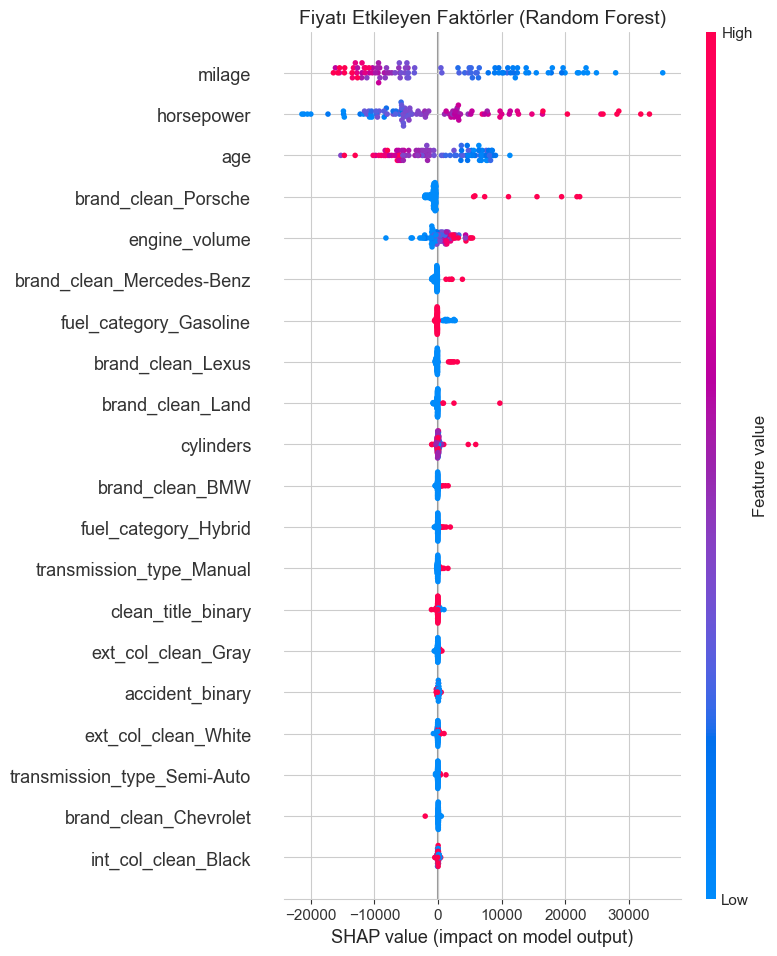

In [6]:
from sklearn.ensemble import RandomForestRegressor
import shap

# 1. Random Forest Modelini Eğit
print("Random Forest modeli eğitiliyor (Bu model SHAP ile tam uyumludur)...")
rf_model = RandomForestRegressor(n_estimators=100, max_depth=20, random_state=42)
rf_model.fit(X_train, y_train)
print("Model eğitimi tamamlandı.")

# 2. SHAP Analizi
print("SHAP değerleri hesaplanıyor...")
explainer = shap.TreeExplainer(rf_model)

# Performans için test setinden sadece 100 örnek alalım (Tüm veri yavaş olabilir)
X_sample = X_test.sample(100, random_state=42)
shap_values = explainer.shap_values(X_sample)

print("SHAP hesaplaması BAŞARILI!")

# 3. Görselleştirme
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_sample, show=False)
plt.title("Fiyatı Etkileyen Faktörler (Random Forest)", fontsize=14)
plt.show()

Random Forest modeli eğitiliyor (Lütfen bekleyiniz)...
Model eğitimi tamamlandı.

--- SEÇİLEN ARAÇ İÇİN TAHMİN RAPORU ---
Gerçek Fiyat       : $35,900
Modelin Tahmini    : $36,342
Fark (Hata)        : $442
----------------------------------------
SHAP analizi hazırlanıyor...


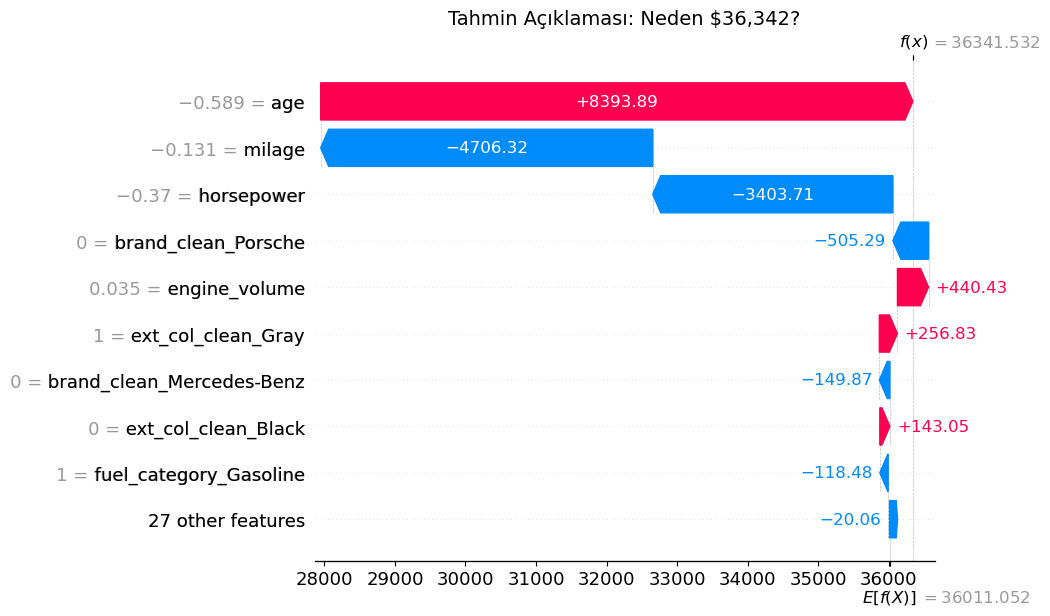

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split


# İşlenmiş veriyi yüklüyoruz
csv_path = 'processed_used_cars_ready_for_model.csv'
df = pd.read_csv(csv_path)

X = df.drop(['price'], axis=1, errors='ignore')
y = df['price']

# Eğitim ve Test ayrımı
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

#RANDOM FOREST MODELİNİ EĞİT
print("Random Forest modeli eğitiliyor (Lütfen bekleyiniz)...")

rf_model = RandomForestRegressor(
    n_estimators=100,  # 100 adet karar ağacı
    max_depth=20,      # Ağaç derinliği
    random_state=42,
    n_jobs=-1          # Tüm işlemcileri kullan
)

rf_model.fit(X_train, y_train)
print("Model eğitimi tamamlandı.")

# RASTGELE BİR ARAÇ SEÇİMİ VE TAHMİN YAPMA
# Farklı araçlar denemek için buradaki sayıları değiştirilebilir (0, 10, 50 vb.)
secilen_index =1

secilen_arac_verisi = X_test.iloc[[secilen_index]]
gercek_fiyat = y_test.iloc[secilen_index]
tahmin_edilen_fiyat = rf_model.predict(secilen_arac_verisi)[0]

print(f"\n--- SEÇİLEN ARAÇ İÇİN TAHMİN RAPORU ---")
print(f"Gerçek Fiyat       : ${gercek_fiyat:,.0f}")
print(f"Modelin Tahmini    : ${tahmin_edilen_fiyat:,.0f}")
print(f"Fark (Hata)        : ${tahmin_edilen_fiyat - gercek_fiyat:,.0f}")
print("-" * 40)

# NEDEN BU FİYAT? (SHAP WATERFALL ANALİZİ)
print("SHAP analizi hazırlanıyor...")

# Random Forest için Explainer oluştur
explainer = shap.TreeExplainer(rf_model)

# Sadece seçilen araç için SHAP değerlerini hesapla
shap_values_single = explainer(secilen_arac_verisi)

# GRAFİK ÇİZİMİ (Waterfall)
plt.figure(figsize=(10, 6))
shap.plots.waterfall(shap_values_single[0], show=False)

# Başlık ekle
plt.title(f"Tahmin Açıklaması: Neden ${tahmin_edilen_fiyat:,.0f}?", fontsize=14)
plt.show()

Çıkan Grafik Nasıl Okunur?Bu grafik (Waterfall Plot), 
modelin karar verme hikayesini anlatır:$E[f(X)]$ (Alt Kısım): Bu, modelinizin gördüğü ortalama araba fiyatıdır (Başlangıç noktası). 

Örneğin: $35,000.Kırmızı Barlar (Pozitif Etki): Fiyatı yukarı çeken özelliklerdir.Örnek: model_year (Model Yılı) 2022 ise, bu özellik fiyatı +$10,000 artırmış olabilir.Mavi Barlar (Negatif Etki): Fiyatı aşağı çeken özelliklerdir.Örnek: milage (Kilometre) yüksekse veya 

accident (Kaza) varsa, fiyatı -$5,000 düşürmüş olabilir.$f(x)$ (Üst Kısım): Tüm artış ve azalışların sonucunda modelin ulaştığı son tahmin fiyatıdır.Bu analiz, projenizi sunarken "Modelimiz sadece tahmin yapmıyor, nedenini de biliyor" demenizi sağlayan en güçlü kanıttır.

SVR modeli eğitiliyor (Bu işlem veri boyutuna göre biraz sürebilir)...
Model eğitimi tamamlandı.

--- SEÇİLEN ARAÇ İÇİN SVR TAHMİN RAPORU ---
Gerçek Fiyat       : $47,500
SVR Tahmini        : $48,594
Fark (Hata)        : $1,094
----------------------------------------
SHAP analizi hazırlanıyor (KernelExplainer yavaş olabilir, özet veri kullanılıyor)...


c:\Users\ysfygc\anaconda3\envs\BTK\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=13.
  warnings.warn(


  0%|          | 0/1 [00:00<?, ?it/s]

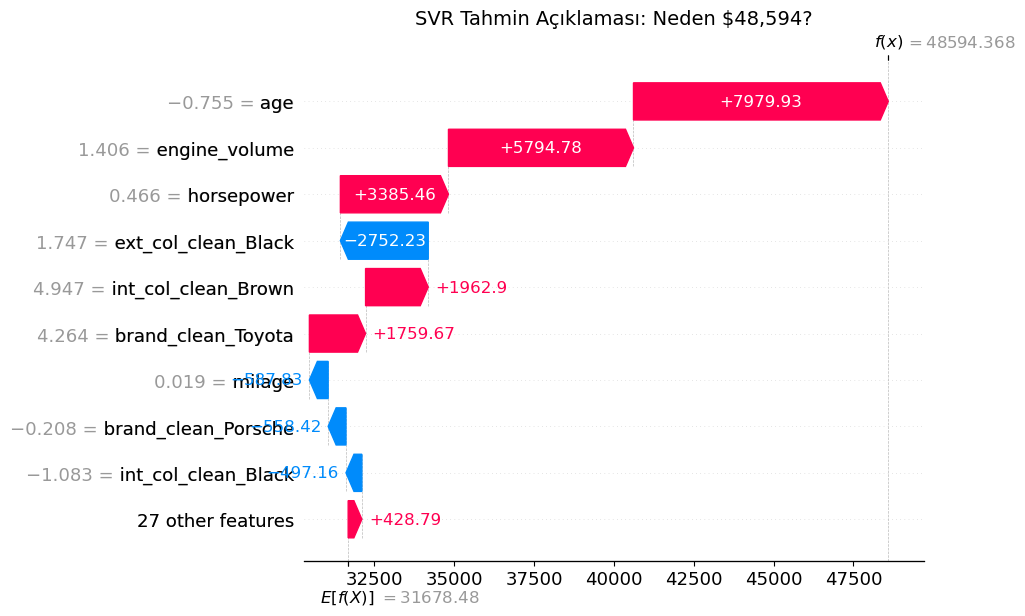

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# 1. VERİ YÜKLEME
# ---------------------------------------------------------
csv_path = 'processed_used_cars_ready_for_model.csv'
df = pd.read_csv(csv_path)

X = df.drop(['price'], axis=1, errors='ignore')
y = df['price']

# 2. VERİ BÖLME VE ÖLÇEKLENDİRME (SVR İÇİN ZORUNLU ADIM)
# ---------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# SVR, verilerin aynı ölçekte olmasını ister (Standartlaştırma)
scaler = StandardScaler()

# Train setine 'fit' (öğren) ve 'transform' (uygula) yapıyoruz
X_train_scaled = scaler.fit_transform(X_train)

# Test setine SADECE 'transform' yapıyoruz (Data Leakage olmasın diye)
X_test_scaled = scaler.transform(X_test)

# Sütun isimlerini kaybetmemek için tekrar DataFrame yapalım (SHAP için önemli)
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X_test.columns)

# 3. SVR MODELİNİ EĞİTME
# ---------------------------------------------------------
print("SVR modeli eğitiliyor (Bu işlem veri boyutuna göre biraz sürebilir)...")

# Kernel='rbf': Doğrusal olmayan ilişkileri yakalamak için standart
# C: Hata toleransı (Büyük C = Hata yapmamaya zorlar, Küçük C = Daha esnek)
# epsilon: Hatanın göz ardı edileceği aralık
svr_model = SVR(kernel='rbf', C=10000, epsilon=0.1) 

svr_model.fit(X_train_scaled_df, y_train)
print("Model eğitimi tamamlandı.")

# 4. TAHMİN VE RAPORLAMA
# ---------------------------------------------------------
secilen_index = 8

# Ölçeklendirilmiş veriden seçiyoruz
secilen_arac_verisi_scaled = X_test_scaled_df.iloc[[secilen_index]] 

gercek_fiyat = y_test.iloc[secilen_index]
tahmin_edilen_fiyat = svr_model.predict(secilen_arac_verisi_scaled)[0]

print(f"\n--- SEÇİLEN ARAÇ İÇİN SVR TAHMİN RAPORU ---")
print(f"Gerçek Fiyat       : ${gercek_fiyat:,.0f}")
print(f"SVR Tahmini        : ${tahmin_edilen_fiyat:,.0f}")
print(f"Fark (Hata)        : ${tahmin_edilen_fiyat - gercek_fiyat:,.0f}")
print("-" * 40)

# 5. SHAP ANALİZİ (KernelExplainer ile)
# ---------------------------------------------------------
print("SHAP analizi hazırlanıyor (KernelExplainer yavaş olabilir, özet veri kullanılıyor)...")

# SVR ağaç tabanlı olmadığı için TreeExplainer kullanamayız.
# KernelExplainer kullanacağız. Hızlandırmak için tüm veri yerine
# verinin bir özetini (kmeans ile kümelenmiş merkezlerini) veriyoruz.
X_train_summary = shap.kmeans(X_train_scaled_df, 10) 

explainer = shap.KernelExplainer(svr_model.predict, X_train_summary)

# Sadece seçilen araç için hesapla
shap_values_single = explainer.shap_values(secilen_arac_verisi_scaled)

# SHAP Kütüphanesinin güncel versiyonlarında KernelExplainer çıktısı bazen liste döner
# Boyut uyumsuzluğu olursa düzeltmek gerekebilir
if isinstance(shap_values_single, list):
    shap_values_single = shap_values_single[0]

# GRAFİK ÇİZİMİ (Waterfall)
# KernelExplainer doğrudan Explanation objesi döndürmediği için manuel oluşturuyoruz
exp = shap.Explanation(
    values=shap_values_single[0], # Tekil değerler
    base_values=explainer.expected_value, # Ortalama değer
    data=secilen_arac_verisi_scaled.values[0], # Girdi verisi
    feature_names=X_test.columns # Sütun isimleri
)

plt.figure(figsize=(10, 6))
shap.plots.waterfall(exp, show=False)
plt.title(f"SVR Tahmin Açıklaması: Neden ${tahmin_edilen_fiyat:,.0f}?", fontsize=14)
plt.show()